In [1]:
import os
import glob
import itertools
import numpy as np
import pandas as pd


import matplotlib.pyplot as plt
from scipy.stats import pearsonr
from scipy.signal import chirp, find_peaks, peak_widths

In [3]:
# 定义函数

def separate_session(df, threshold=3):
    df = pd.read_csv(df, index_col=0)
    df['index_col'] = pd.to_numeric(df.index, errors='coerce')
    check_points = [0]  # 初始化第一个分割点为0（DataFrame的起始位置）
    frame_list = df['index_col'].values.tolist()
    

    # 判断两行之间的时间差，大于threshold则视为新的session
    for i in range(len(frame_list) - 1):
        if (frame_list[i+1] - frame_list[i]) > threshold:
            check_points.append(frame_list[i+1])
    
    check_points.append(frame_list[-1] + 1)  # 添加最后一个分割点

    session_dfs = []
    for i in range(len(check_points) - 1):
        session_df = df[(df['index_col'] >= check_points[i]) & (df['index_col'] < check_points[i+1])]
        session_df.drop(columns='index_col', inplace=True)
        session_dfs.append(session_df)

    return session_dfs
   
 

# 处理分离后的session文件，使每个session的开始时间为0
def process_frame(df):
    # 获取DataFrame的index并转换为float类型的list
    index_list = [float(index) for index in df.index]

    # 判断第一个index的值是否为0，并进行相应处理
    if index_list[0] != 0:
        # 如果第一个index的值不为0，将所有index值减去第一个index值，以实现“相对于第一个index的增量”效果
        index_list = [index - index_list[0] for index in index_list]

    return index_list

  
def process_event_interval(df):
    # 从DataFrame中提取'From Second'和'To Second'列，并转换为二维列表
    event_list = df[['From Second', 'To Second']].values.tolist()

    # 返回处理后的新事件列表
    return event_list



# 获得事件标记
def get_event_label(event_df):
    
    '''
    Aim:
        for OFT
        translate 'event' in eventFile to integer label
        each row (corresponding to each time interval) of event is assigned a label
        called in function `add_event_label()`
    '''
    
    # get event status list
    Event_status = event_df['Event'].values.tolist()
    # compact event label list for three sessions
    event_label = []
    for i in Event_status:   
        if i.strip() == 'free_allogroom':
            event_label.append(11)
        elif i.strip() == 'sniff' :
            event_label.append(12)
        elif i.strip() == 'rear_selfgroom':
            event_label.append(21)
        elif i.strip() == 'all':
            event_label.append(22)
        else:
            event_label.append(23)

    return(event_label)


# 添加事件标签
def add_event_label(trace_df, event_path):

    '''
    Aim:
        add event_label to each frame
        one frame can have several label (since mouse can in a location and do something)
    
    Retrun:
        trace dataframe with one label column
    '''
    
    frame_list = process_frame(trace_df)
    #get event dataframe/eventIntervals/eventLabel
#     event_df = pd.read_csv(event_path)
    event_df = pd.read_excel(event_path)
    interval_list = process_event_interval(event_df)
    event_label = get_event_label(event_df)

    
    # add label to each frame
    frame_label_list = []
    for frame in frame_list:
        frame_label = str()
        
        for i in range(len(interval_list)): # one frame can be in several interval
            if min(interval_list[i])  <= frame <= max(interval_list[i]) :
                frame_label = frame_label+ str(event_label[i])

        # convert str to int
        if len(frame_label) == 0:
            frame_label = np.nan
        else:
            frame_label = int(frame_label)

        # append frame label to list
        frame_label_list.append(frame_label)
    
    
    # add label list to trace df 
    new_df = trace_df.copy()
    new_df['Frame_Label']  =  frame_label_list
    new_df = new_df.dropna()
    

    return(new_df)


In [4]:
# 检查特定状态下的帧间隔，并返回满足条件的数据子集
def check_frame_interval(df, which_status_to_check_frame):
    
    # set up which_status_to_check_frame
    
    if which_status_to_check_frame == 'free_allogroom':
        which_status_to_check_frame = str(11)
    elif which_status_to_check_frame == 'sniff':
        which_status_to_check_frame = str(12)
    elif which_status_to_check_frame == 'rear_selfgroom':
        which_status_to_check_frame = str(21)
    elif which_status_to_check_frame == 'all':
        which_status_to_check_frame = str(22)
    else:
        raise ValueError('Not approved status. choose from: Investigating_RIGHT_SNIFF, Investigating_LEFT_SNIFF, In_right, In_all, In_left')

    #df = add_event_label(df, event_1_path, event_2_path, event_3_path, mice_path)[which_session]
    frame_label_list = df['Frame_Label'].values.tolist()
    
    # to separate status label, eg:20214111
    n = 2
    
    check_frame_label_list = []
    for line in frame_label_list:
        line = str(line)
        line_list= [line[i:i+n] for i in range(0, len(line), n)]
        if which_status_to_check_frame in line_list:
            check_frame_label_list.append(1)
        else:
            check_frame_label_list.append(0)       
            
    
            
    df['status'] = check_frame_label_list
    df_keep = df[ (df['status'] == 1)]
    df_keep = df_keep.drop('status', axis = 1)
    df_keep = df_keep.drop('Frame_Label', axis = 1)
    
    print('the shape of the dataframe in the status is:', df_keep.shape)
    print(df_keep.head(3))
    return(df_keep)
    


In [5]:
# 计算给定数据框中每两个单元格之间的相关性，并返回相关性值的列表
def corr_list(df):
    end_range = df.shape[1]  # 获取数据框的列数
    corr_list = []  # 初始化存储相关性值的列表
    
    # 检查数据框的行数是否大于2，如果是，则继续执行相关性计算
    if df.shape[0] > 2:
        # 将数据框中的值转换为浮点数，以便进行计算
        df = df.astype(float)
        
        # 使用两层循环遍历每一对列，计算皮尔逊相关系数
        for i in range(end_range):
            a = i + 1
            for a in range(a, end_range):
                corr, _ = pearsonr(df.iloc[:, i], df.iloc[:, a])  # 计算相关性
                corr_list.append(corr)  # 将相关性值添加到列表中
                
    return corr_list  # 返回相关性值的列表





# def corr_list(df):
#     end_range = df.shape[1]  # 获取数据框的列数
#     corr_list = []  # 初始化存储相关性值的列表
    
#     # 检查数据框的行数是否大于2，如果是，则继续执行相关性计算
#     if df.shape[0] > 2:
#         # 将数据框中的值转换为浮点数，以便进行计算
#         df = df.astype(float)
        
#         # 使用两层循环遍历每一对列，计算皮尔逊相关系数
#         for i in range(end_range):
#             a = i + 1
#             for a in range(a, end_range):
#                 # 获取两列数据
#                 col_i = df.iloc[:, i]
#                 col_a = df.iloc[:, a]
                
#                 # 检查两列是否都是全零
#                 if np.all(col_i == 0) and np.all(col_a == 0):
#                     # 如果两列都是全零，则跳过这对列的计算
#                     continue  # 跳过这对列
                
#                 # 计算相关性
#                 corr, _ = pearsonr(col_i, col_a)
#                 corr_list.append(corr)  # 将相关性值添加到列表中
                
#     return corr_list  # 返回相关性值的列表

# 绘制两个数据序列的直方图并进行比较
def overlaid_histogram(figsize, data1, data2, n_bins=0, data1_name="", data1_color="#539caf",
                       data2_name="", data2_color="#7663b0", x_label="", y_label="", title="",
                       y_limit=None, x_limit=None):
    
    # 计算数据范围和bin宽度，以便公平比较两个分布
    max_nbins = 10
    data_range = [min(min(data1), min(data2)), max(max(data1), max(data2))]
    binwidth = (data_range[1] - data_range[0]) / max_nbins

    # 根据是否提供n_bins参数来设置bin的数量
    if n_bins == 0:
        bins = np.arange(data_range[0], data_range[1] + binwidth, binwidth)
    else:
        bins = n_bins

    # 计算权重，用于绘制百分比直方图
    weights1 = np.ones_like(data1) / float(len(data1))
    weights2 = np.ones_like(data2) / float(len(data2))

    # 创建图
    _, ax = plt.subplots(figsize=figsize)
    
    # 绘制数据1的直方图，设置颜色和透明度，添加权重
    ax.hist(data1, bins=bins, color=data1_color, alpha=1, label=data1_name, weights=weights1)
    
    # 绘制数据2的直方图，设置颜色和透明度，添加权重
    ax.hist(data2, bins=bins, color=data2_color, alpha=0.75, label=data2_name, weights=weights2)

    # 如果提供了y轴上限，设置y轴的上限
    if y_limit:
        ax.set_ylim(0, y_limit)
        
    # 如果提供了x轴范围，设置x轴的范围
    if x_limit:
        ax.set_xlim(-x_limit, x_limit)

    # 隐藏图的右边和上边的坐标轴线
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)

    # 设置坐标轴刻度标签的样式，包括字体和大小
    ax.tick_params(axis='both', which='major', labelsize=20)
    labels = ax.get_yticklabels()
    [label.set_fontname('Arial') for label in labels]
    labels = ax.get_xticklabels()
    [label.set_fontname('Arial') for label in labels]

    # 保存绘制的图像为指定的文件名
    plt.savefig(title)

def FWHM(distribute):
    
    # 计算最佳拟合的 sigma 和 mu 值
    sigma = np.nanstd(distribute)  # 分布的标准差
    mu = np.nanmean(distribute)    # 分布的均值
    
    # 创建一个图形和坐标轴
    fig, ax = plt.subplots()
    
    # 绘制直方图，将数据分为100个区间
    n, bins, patches = ax.hist(distribute, bins=100, density=1)
    
    # 生成最佳拟合曲线，用于直方图的拟合
    y = ((1 / (np.sqrt(2 * np.pi) * sigma)) * np.exp(-0.5 * (1 / sigma * (bins - mu))**2))

    # 计算FWHM
    peaks, _ = find_peaks(y)  # 寻找峰值
    if len(peaks) == 0:  # 如果没有找到峰值，就返回None
        FWHM = None
    else:
        results_half = peak_widths(y, peaks, rel_height=0.5)  # 计算半峰宽
        FWHM = results_half[0][0]  # 只返回数组中的第一个元素
    
    plt.close()  # 关闭绘图，避免显示
    
    return FWHM  # 返回全宽半最大值



# 先独立运行完seperate session,再进行后面的FWHM的分析
只需要参考一只小鼠的处理流程。不同小鼠除了文件保存路径不同外其他代码相同。

# Separate sessions & Save for later use

In [6]:
root_path = 'F:/AAA-ZSY(5)'
data_path = os.path.join(root_path)
# F:/AAA-Social analysis/Data-Neuron Social/AAA-PL/1-PL04-SOCIAL

IL1_list = ['SYN21-ITRT',]
WT_mouse = ['WT']*len(IL1_list)

session_ids = [1,2,3,4,5,6]

In [7]:
#分离不同的session。根据TRACE文件中的'time'列中的值，将不同的session区分开。
def separate_session(df, threshold=3):
    df = pd.read_csv(df, index_col=0)
    
    df.columns = [c.strip() for c in df.columns]  #去除TRACE文件标题列的空格

    df['index_col'] = pd.to_numeric(df.index, errors='coerce')
    check_points = [0]  # 初始化第一个分割点为0（DataFrame的起始位置）
    frame_list = df['index_col'].values.tolist()

    # 判断两行之间的时间差，大于threshold则视为新的session
    for i in range(len(frame_list) - 1):
        if (frame_list[i+1] - frame_list[i]) > threshold:
            check_points.append(frame_list[i+1])
    
    check_points.append(frame_list[-1] + 1)  # 添加最后一个分割点

    session_dfs = []
    for i in range(len(check_points) - 1):
        session_df = df[(df['index_col'] >= check_points[i]) & (df['index_col'] < check_points[i+1])]
        session_df.drop(columns='index_col', inplace=True)
        session_dfs.append(session_df)

    return session_dfs

In [8]:
for i in range(len(IL1_list)):
    
    mouseSummary = IL1_list[i]
    mouseName = mouseSummary[-11:-7]   ### mouse name selected from file name
    mouseType = WT_mouse[i]
    print("Processing ", mouseName+'-'+mouseType)
    
    trace = os.path.join(data_path, mouseSummary, "TRACE_Con.csv")
    df_traces = separate_session(trace)

    for session_id in session_ids:
        event = os.path.join(data_path, mouseSummary, f"event{session_id}.xlsx")
        #onoff = os.path.join(data_path, mouseSummary, project+'ONOFF.csv')
    
        session = df_traces[session_id-1]
        session.index.name="Frame"
        session.index = pd.to_numeric(session.index)
        session_frame_label = add_event_label(session, event)

        session_frame_label.to_csv(os.path.join(data_path, mouseSummary, f"session_{session_id}_trace.csv"))

        print(mouseName, f"session_{session_id}_trace has shape:", session_frame_label.shape)

    print('Done')
    session_frame_label.head(2)   
    
 
    

Processing  SYN-WT


C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2922488257.py:3: DtypeWarning: Columns (0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(df, index_col=0)
C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2922488257.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  session_df.drop(columns='index_col', inplace=True)
C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2922488257.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slic

SYN session_1_trace has shape: (4502, 105)
SYN session_2_trace has shape: (3602, 105)
SYN session_3_trace has shape: (9004, 105)
SYN session_4_trace has shape: (4502, 105)
SYN session_5_trace has shape: (3602, 105)
SYN session_6_trace has shape: (9006, 105)
Done


# FWHM for each mouse

In [10]:
root_path = 'F:/AAA-ZSY(5)'
data_path = os.path.join(root_path)
mice_list = ['SYN15-RTIT','SYN17-RTIT','SYN18-ITRT','SYN19-ITRT','SYN20-ITRT','SYN21-ITRT']
session_ids = [2,3,5,6]   # Which session do you want to analyze?

In [11]:
print('IL')

mice_FWHM_list = []

#whole_1_chain = []
In_all_1_chain = []
sniff_1_chain = []
sniffed_1_chain = []
freezing_1_chain = []
cs_1_chain = []

#whole_2_chain = []
In_all_2_chain = []
sniff_2_chain = []
sniffed_2_chain = []
freezing_2_chain = []
cs_2_chain = []

#whole_3_chain = []
In_all_3_chain = []
sniff_3_chain = []
sniffed_3_chain = []
freezing_3_chain = []
cs_3_chain = []
  
#whole_4_chain = []
In_all_4_chain = []
sniff_4_chain = []
sniffed_4_chain = []
freezing_4_chain = []
cs_4_chain = []

#whole_5_chain = []
In_all_5_chain = []
sniff_5_chain = []
sniffed_5_chain = []
freezing_5_chain = []
cs_5_chain = []

#whole_6_chain = []
In_all_6_chain = []
sniff_6_chain = []
sniffed_6_chain = []
freezing_6_chain = []
cs_6_chain = []

for i in range(len(mice_list)):
    
    mouse_name = mice_list[i]
    mouseSummary = mice_list[i]
   
    
    print('Processing', mouse_name)
    
    #mice = os.path.join(root_path, mouse_name)
    #trace = os.path.join(root_path, mouse_name, "TRACE_Con.csv")
    #event1 = os.path.join(root_path, mouse_name, "event1_Con.xlsx_process.xlsx")
    #event2 = os.path.join(root_path, mouse_name, "event2_Con.xlsx_process.xlsx")
    #event3 = os.path.join(root_path, mouse_name, "event3_Con.xlsx_process.xlsx")

    
    # 选择FPS
    if mouse_name.split('_')[0] in ['PL1-4sessions',]:
        fps = 15
    else:
        fps = 15
        
    #dfLabeled, session_1, session_2, session_3 = add_event_label(trace, event1, event2, event3)
    #session_list = [session_1, session_2, session_3]
    sessionName_list = ['session_1', 'session_2', 'session_3', 'session_4', 'session_5', 'session_6']
    
    
    #for session_index in range(len(sessionName_list)):
    for sessionID in session_ids:
            
            
            event = os.path.join(data_path, mouseSummary, f"event{sessionID}.xlsx")
            session = pd.read_csv(os.path.join(data_path, mouseSummary, f"session_{sessionID}_trace.csv"))
            #session = session_list[session_index]
            sessionName = sessionName_list[sessionID-1]
            
            
            #whole_df = session.drop('Frame_Label', axis=1)  
            #In_all_df = check_frame_interval(session, 'In_all')
            sniff_df = check_frame_interval(session, 'free_allogroom')           ### RT1 and RET do not use this line
            sniffed_df = check_frame_interval(session, 'sniff')       ### RT1 and RET do not use this line
            freezing_df = check_frame_interval(session, 'rear_selfgroom')   
            cs_df = check_frame_interval(session, 'all') 


            #whole_corrs = corr_list(whole_df)
            #In_all_corrs = corr_list(In_all_df)
            sniff_corrs = corr_list(sniff_df)         ### RT1 and RET do not use this line
            sniffed_corrs = corr_list(sniffed_df)     ### RT1 and RET do not use this line
            freezing_corrs = corr_list(freezing_df)
            cs_corrs = corr_list(cs_df)


            # loop and update chain
            if sessionName == 'session_1':
                #whole_1_chain = itertools.chain(whole_1_chain,whole_corrs)
                #In_all_1_chain = itertools.chain(In_all_1_chain,In_all_corrs)
                sniff_1_chain = itertools.chain(sniff_1_chain,sniff_corrs)
                sniffed_1_chain = itertools.chain(sniffed_1_chain,sniffed_corrs)
                freezing_1_chain = itertools.chain(freezing_1_chain,freezing_corrs)
                cs_1_chain = itertools.chain(cs_1_chain,cs_corrs)
            elif sessionName == 'session_2':
                #whole_2_chain = itertools.chain(whole_2_chain,whole_corrs)
                #In_all_2_chain = itertools.chain(In_all_2_chain,In_all_corrs)
                sniff_2_chain = itertools.chain(sniff_2_chain,sniff_corrs)
                sniffed_2_chain = itertools.chain(sniffed_2_chain,sniffed_corrs)
                freezing_2_chain = itertools.chain(freezing_2_chain,freezing_corrs)
                cs_2_chain = itertools.chain(cs_2_chain,cs_corrs)
            elif sessionName == 'session_3':
                #whole_3_chain = itertools.chain(whole_3_chain,whole_corrs)
                #In_all_3_chain = itertools.chain(In_all_3_chain,In_all_corrs)
                sniff_3_chain = itertools.chain(sniff_3_chain,sniff_corrs)
                sniffed_3_chain = itertools.chain(sniffed_3_chain,sniffed_corrs)
                freezing_3_chain = itertools.chain(freezing_3_chain,freezing_corrs)
                cs_3_chain = itertools.chain(cs_3_chain,cs_corrs)
            elif sessionName == 'session_4':
                #whole_4_chain = itertools.chain(whole_4_chain,whole_corrs)
                #In_all_4_chain = itertools.chain(In_all_4_chain,In_all_corrs)
                sniff_4_chain = itertools.chain(sniff_4_chain,sniff_corrs)
                sniffed_4_chain = itertools.chain(sniffed_4_chain,sniffed_corrs)
                freezing_4_chain = itertools.chain(freezing_4_chain,freezing_corrs)
                cs_3_chain = itertools.chain(cs_3_chain,cs_corrs)
            elif sessionName == 'session_5':
                #whole_5_chain = itertools.chain(whole_5_chain,whole_corrs)
                #In_all_5_chain = itertools.chain(In_all_5_chain,In_all_corrs)
                sniff_5_chain = itertools.chain(sniff_5_chain,sniff_corrs)
                sniffed_5_chain = itertools.chain(sniffed_5_chain,sniffed_corrs)
                freezing_5_chain = itertools.chain(freezing_5_chain,freezing_corrs)
                cs_5_chain = itertools.chain(cs_5_chain,cs_corrs)
            else :
                #whole_6_chain = itertools.chain(whole_6_chain,whole_corrs)
                #In_all_6_chain = itertools.chain(In_all_6_chain,In_all_corrs)
                sniff_6_chain = itertools.chain(sniff_6_chain,sniff_corrs)
                sniffed_6_chain = itertools.chain(sniffed_6_chain,sniffed_corrs)
                freezing_6_chain = itertools.chain(freezing_6_chain,freezing_corrs)
                cs_6_chain = itertools.chain(cs_6_chain,cs_corrs)
        
            # # 绘图
            # figsize = (6,6)
            # title = mouse_name+"_"+sessionName+"free_allogroom VS. rear_selfgroom"
            # overlaid_histogram(figsize, sniff_corrs, freezing_corrs, n_bins = 200, 
            #                 data1_name="free_allogroom", data1_color="red", 
            #                 data2_name="rear_selfgroom", data2_color="blue") # 在这里改颜色
            # plt.title(title)          # 添加标题
            # plt.xlabel("Correlation") # 添加X轴标签
            # plt.ylabel("P")           # 添加Y轴标签
            # plt.savefig(f'F:/AAA-ZSY(5)/Results/FWHM/{title}.png')  # 保存图像 C:\Users\DELL\Desktop\pl14new
            # plt.show()


            #figsize = (6,6)
            #title = mouse_name+"_"+sessionName+" sniff VS. all"
            #overlaid_histogram(figsize,sniffed_corrs, cs_corrs, n_bins = 200, 
            #                data1_name="sniff", data1_color="red", 
            #                data2_name="all", data2_color="blue")
            #plt.title(title)          # 添加标题
            #plt.xlabel("Correlation") # 添加X轴标签
            #plt.ylabel("P")           # 添加Y轴标签
            #plt.savefig(f'F:/AAA-ZSY(5)/Results/FWHM/{title}.png')  # 保存图像
            #plt.show()

            # save FWHM
            FWHM_dic = {'mouseName':mouse_name,
                        'whichSession':sessionName,
                        #'whole FWHM':FWHM(whole_corrs),
                        #'In_all FWHM':FWHM(In_all_corrs),
                        'free_allogroom FWHM':FWHM(sniff_corrs),
                        'sniff FWHM':FWHM(sniffed_corrs),
                        'rear_selfgroom FWHM':FWHM(freezing_corrs),
                        'all FWHM':FWHM(cs_corrs)}
            mice_FWHM = pd.DataFrame.from_dict(FWHM_dic, orient='index').T
            mice_FWHM_list.append(mice_FWHM)

mice_FWHM_DF = pd.concat(mice_FWHM_list)
mice_FWHM_DF.to_csv('F:/AAA-ZSY(5)/Results/FWHM/FWHM_11111.csv')


IL
Processing SYN15-RTIT
the shape of the dataframe in the status is: (1658, 117)
        Frame      C000      C001      C002      C003      C004      C005  \
0  366.990000  0.451622 -0.268487  0.191600 -0.675698  1.126721  0.674422   
1  367.056627  0.219997 -0.122553  0.245240 -0.826678  0.971318  0.713816   
2  367.123255  0.082652 -0.364793  0.213901 -0.779392  1.150727  0.728816   

       C006      C008      C009  ...  C183  C186  C189  C191  C193  C205  \
0  0.446717 -0.413191  1.469597  ...     0     0     0     0     0     0   
1  0.151411 -0.716625  1.410162  ...     0     0     0     0     0     0   
2  0.353191 -0.762199  1.473629  ...     0     0     0     0     0     0   

   C206  C208  C217  C218  
0     0     0     0     0  
1     0     0     0     0  
2     0     0     0     0  

[3 rows x 117 columns]
the shape of the dataframe in the status is: (15, 117)
          Frame      C000      C001      C002      C003      C004      C005  \
779  418.892786  0.649908 -0.95876

C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2556084886.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(df.iloc[:, i], df.iloc[:, a])  # 计算相关性


the shape of the dataframe in the status is: (90, 117)
           Frame      C000      C001      C002      C003      C004      C005  \
4098  960.348333 -0.252501 -1.054323 -0.680804 -0.678237  0.159441  1.149162   
4099  960.414961 -0.092676 -0.767223 -0.610583 -0.619565  0.132055  1.405466   
4100  960.481588 -0.029635 -0.858939 -0.791732 -0.825323  0.113882  1.534345   

          C006      C008      C009  ...  C183  C186  C189  C191  C193  C205  \
4098  0.499947  5.682720 -0.241554  ...   0.0   0.0   0.0   0.0   0.0   0.0   
4099  0.427979  5.509015  0.340169  ...   0.0   0.0   0.0   0.0   0.0   0.0   
4100  0.604123  5.338674  0.405532  ...   0.0   0.0   0.0   0.0   0.0   0.0   

      C206  C208  C217  C218  
4098   0.0   0.0   0.0   0.0  
4099   0.0   0.0   0.0   0.0  
4100   0.0   0.0   0.0   0.0  

[3 rows x 117 columns]
the shape of the dataframe in the status is: (75, 117)
          Frame      C000      C001      C002      C003      C004      C005  \
331  709.362689  0.336577

C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2556084886.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(df.iloc[:, i], df.iloc[:, a])  # 计算相关性


the shape of the dataframe in the status is: (1041, 117)
             Frame      C000      C001      C002      C003      C004  C005  \
143  777898.281702  0.616506  0.677508 -1.210434 -0.450481  0.059126   0.0   
144  777898.348329  0.583178  1.012218 -0.907194 -0.741890 -1.132897   0.0   
145  777898.414957  0.309117  0.803348 -0.943500 -0.806360 -0.788641   0.0   

         C006      C008      C009  ...      C183      C186      C189  \
143 -0.404366 -1.347294 -0.735253  ... -0.010006  1.550137 -0.182097   
144 -0.367023 -1.318254 -0.771065  ...  0.088940  1.831760 -0.250220   
145 -0.473811 -1.344323 -0.718832  ... -0.247539  1.901223 -0.316903   

         C191      C193      C205      C206      C208      C217      C218  
143  0.321711 -0.088374 -0.774381  0.464795 -0.631422  1.361272 -0.520682  
144  0.123950 -0.040551 -1.228302  0.333531 -0.431430  1.644418 -0.827655  
145  0.142315  0.103587 -0.798180  0.354156 -0.637962  1.694330 -0.726490  

[3 rows x 117 columns]
the shape of 

C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2556084886.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(df.iloc[:, i], df.iloc[:, a])  # 计算相关性


... (32 outputs left out)

the shape of the dataframe in the status is: (859, 105)
             Frame      C000      C001      C002      C003      C004  \
101  691463.074344 -0.316195 -0.235476 -0.320536 -0.120299  0.767712   
102  691463.140971 -0.471048  0.035756 -0.540221 -0.204154  0.987432   
103  691463.207598 -0.222529  0.388333 -0.347034 -0.153445  0.877647   

         C005      C006  C007      C008  ...      C129      C133      C134  \
101 -0.442745 -0.281612   0.0  0.127277  ... -1.826123 -1.230723  0.413201   
102 -0.287206 -0.395770   0.0 -0.021737  ... -1.918031 -1.447237  0.173512   
103 -0.249242 -0.157884   0.0 -0.193713  ... -1.841077 -1.271536 -0.148414   

         C135      C136      C139      C142      C143      C151      C165  
101 -0.751864  0.723951 -0.290250 -0.305591  0.678315 -0.411450  1.003692  
102 -0.207806  0.760374 -0.249123  0.288798  0.092938 -0.274658  0.770969  
103 -0.226307  0.472887 -0.078026  0.152932 -0.707952  0.004062  0.455158  

[3 rows x 105 columns]
the shape of t

C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2556084886.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(df.iloc[:, i], df.iloc[:, a])  # 计算相关性


the shape of the dataframe in the status is: (45, 105)
              Frame      C000      C001      C002      C003      C004  \
3693  691996.696371 -0.334415 -0.387510 -0.938170 -0.816352 -1.373562   
3694  691996.762999 -0.507579 -0.363392 -0.730230 -0.413427 -0.726159   
3695  691996.829626  0.008764 -1.125921 -0.667985 -0.633169 -0.209984   

          C005      C006  C007      C008  ...      C129      C133      C134  \
3693  0.402973  0.312708     0 -0.598847  ... -1.396754 -0.248030  0.193612   
3694  0.322713  0.399125     0 -0.159540  ... -1.456469 -0.360593  0.806212   
3695  0.372645 -0.169763     0 -0.489239  ... -1.296684 -0.323135  0.729158   

          C135      C136      C139      C142      C143      C151      C165  
3693  0.223033 -0.551313 -0.651160 -0.480974 -0.137875 -0.648088  0.829173  
3694  0.275533 -0.496269 -0.779627 -0.377661  0.553288 -0.309392 -0.089139  
3695  0.240523 -0.344923 -0.917543 -0.620803  0.854774 -0.398870 -0.495512  

[3 rows x 105 columns]
the

C:\Users\DELL\AppData\Local\Temp\ipykernel_37580\2556084886.py:15: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corr, _ = pearsonr(df.iloc[:, i], df.iloc[:, a])  # 计算相关性


# FWHM for all mice

ValueError: Format ' rear_selfgroom' is not supported (supported formats: eps, jpeg, jpg, pdf, pgf, png, ps, raw, rgba, svg, svgz, tif, tiff)

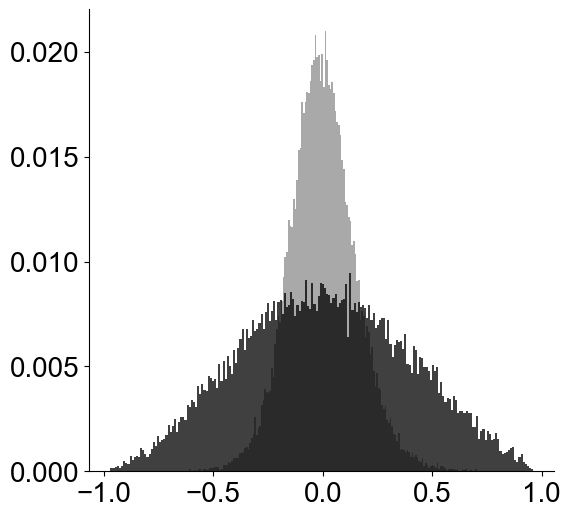

In [12]:
sniff_1_list = list(sniff_1_chain)
freezing_1_list = list(freezing_1_chain)
#In_right_1_chain = []
#In_left_1_chain = []
#In_all_1_chain = []
sniff_2_list = list(sniff_2_chain)
freezing_2_list = list(freezing_2_chain)
#In_right_2_chain = []
#In_left_2_chain = []
#In_all_2_chain = []
sniff_3_list = list(sniff_3_chain)
freezing_3_list = list(freezing_3_chain)
#In_right_3_chain = []
#In_left_3_chain = []
#In_all_3_chain = []
sniff_4_list = list(sniff_4_chain)
freezing_4_list = list(freezing_4_chain)

sniff_5_list = list(sniff_5_chain)
freezing_5_list = list(freezing_5_chain)

sniff_6_list = list(sniff_6_chain)
freezing_6_list = list(freezing_6_chain)


figsize = (6,6)
overlaid_histogram(figsize, sniff_2_list, freezing_2_list, n_bins = 200, 
                   data1_name="WT_Object", data1_color="darkgray", 
                   data2_name="WT_Social", data2_color="black", 
                   x_label="Pearson Correlation Coefficient Distribution", y_label="Probability",
                   title="session2 free_allogroom VS. rear_selfgroom")

overlaid_histogram(figsize, sniff_3_list, freezing_3_list, n_bins = 200, 
                   data1_name="WT_Object", data1_color="black", 
                   data2_name="WT_Social", data2_color="darkgray", 
                   x_label="Pearson Correlation Coefficient Distribution", y_label="Probability",
                   title="session3 free_allogroom VS. rear_selfgroom")

overlaid_histogram(figsize, sniff_5_list, freezing_5_list, n_bins = 200, 
                   data1_name="WT_Object", data1_color="black", 
                   data2_name="WT_Social", data2_color="lightblue", 
                   x_label="Pearson Correlation Coefficient Distribution", y_label="Probability",
                   title="session5 free_allogroom VS. rear_selfgroom")

overlaid_histogram(figsize, sniff_6_list, freezing_6_list, n_bins = 200, 
                   data1_name="WT_Object", data1_color="black", 
                   data2_name="WT_Social", data2_color="lightblue", 
                   x_label="Pearson Correlation Coefficient Distribution", y_label="Probability",
                   title="session6 free_allogroom VS. rear_selfgroom")

allFWHM_dic = {'mouseType':'WT',
            'whichSession':'session 2',
            'sniff FWHM':FWHM(sniff_2_list),
            'sniffed FWHM':FWHM(freezing_2_list),
            'whichSession':'session 3',
            'freezing FWHM':FWHM(sniff_3_list),
            'cs FWHM':FWHM(freezing_3_list),
            'whichSession':'session 5',
            'sniff FWHM':FWHM(sniff_5_list),
            'sniffed FWHM':FWHM(freezing_5_list),
            'whichSession':'session 6',
            'freezing FWHM':FWHM(sniff_6_list),
            'cs FWHM':FWHM(freezing_6_list)}
            
WT_FWHM_All = pd.DataFrame.from_dict(allFWHM_dic, orient='index').T
WT_FWHM_All.to_csv('F:/AAA-ZSY(5)/Results/FWHM/FWHM_All_mice.csv')